Cellule 1 — Créer la session

In [1]:
from decimal import Decimal

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    IntegerType,
    DoubleType,
    DecimalType,
    TimestampType,
)

spark = (
    SparkSession.builder
    .master("spark://spark-master:7077")
    .appName("Bilal-Partie3-SparkSQL")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("WARN")

print("Application :", sc.appName)
print("Master :", sc.master)
print("Spark :", spark.version)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 20:33:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Application : Bilal-Partie3-SparkSQL
Master : spark://spark-master:7077
Spark : 3.5.8


Cellule 2 — Définir les deux schémas

amount_mad utilise DecimalType(12, 2) pour conserver les centimes. courier_id peut être nul, notamment pour les événements CREATED et CANCELLED.

In [2]:
orders_schema = StructType([
    StructField("order_id", StringType(), True),
    StructField("restaurant_id", StringType(), True),
    StructField("customer_id", StringType(), True),
    StructField("city", StringType(), True),
    StructField("status", StringType(), True),
    StructField("amount_mad", DecimalType(12, 2), True),
    StructField("items_count", IntegerType(), True),
    StructField("distance_km", DoubleType(), True),
    StructField("courier_id", StringType(), True),
    StructField("event_time", TimestampType(), True),
])

restaurants_schema = StructType([
    StructField("restaurant_id", StringType(), True),
    StructField("name", StringType(), True),
    StructField("city", StringType(), True),
    StructField("category", StringType(), True),
    StructField("lat", DoubleType(), True),
    StructField("lon", DoubleType(), True),
])

Les champs sont déclarés nullable pour la lecture. Les contrôles de la cellule suivante vérifient les valeurs indispensables au calcul.

Cellule 3 — Lire et vérifier les DataFrames

Ton restaurants.json contient un tableau JSON réparti sur plusieurs lignes. Il faut donc activer multiLine pour ce fichier. L’historique utilise le format JSONL avec un événement par ligne.

In [3]:
orders_path = "s3a://lake/bronze/history/orders_history.jsonl"
restaurants_path = "s3a://lake/bronze/reference/restaurants.json"

orders_df = (
    spark.read
    .schema(orders_schema)
    .option("mode", "FAILFAST")
    .json(orders_path)
)

restaurants_df = (
    spark.read
    .schema(restaurants_schema)
    .option("multiLine", True)
    .option("mode", "FAILFAST")
    .json(restaurants_path)
)

orders_count = orders_df.count()
restaurants_count = restaurants_df.count()

print("Événements :", orders_count)
print("Restaurants :", restaurants_count)

assert orders_count == 50_000
assert restaurants_count == 200

invalid_orders = orders_df.filter(
    F.col("order_id").isNull()
    | F.col("restaurant_id").isNull()
    | F.col("city").isNull()
    | F.col("status").isNull()
    | F.col("amount_mad").isNull()
    | F.col("event_time").isNull()
)

assert invalid_orders.count() == 0

assert restaurants_df.filter(
    F.col("restaurant_id").isNull()
    | F.col("category").isNull()
).count() == 0

assert restaurants_df.select("restaurant_id").distinct().count() == 200

orders_df.printSchema()
restaurants_df.printSchema()
orders_df.show(5, truncate=False)

26/11/20 20:34:11 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties
                                                                                

Événements : 50000
Restaurants : 200


root
 |-- order_id: string (nullable = true)
 |-- restaurant_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- city: string (nullable = true)
 |-- status: string (nullable = true)
 |-- amount_mad: decimal(12,2) (nullable = true)
 |-- items_count: integer (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- courier_id: string (nullable = true)
 |-- event_time: timestamp (nullable = true)

root
 |-- restaurant_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- category: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)

+------------+-------------+--------------+----------+---------+----------+-----------+-----------+-----------+-------------------+
|order_id    |restaurant_id|customer_id   |city      |status   |amount_mad|items_count|distance_km|courier_id |event_time         |
+------------+-------------+--------------+----------+---------+--------

Cellule 4 — Calculer les indicateurs avec l’API DataFrame

In [4]:
delivered_df = orders_df.filter(F.col("status") == "DELIVERED")

city_kpi_df = (
    delivered_df
    .groupBy("city")
    .agg(
        F.count("*").alias("delivered_events"),
        F.sum("amount_mad").alias("revenue_mad"),
        F.round(F.avg("amount_mad"), 2).alias("average_basket_mad"),
    )
    .orderBy("city")
)

city_kpi_df.show(truncate=False)

totals = city_kpi_df.agg(
    F.sum("delivered_events").alias("delivered_events"),
    F.sum("revenue_mad").alias("revenue_mad"),
).first()

assert totals.delivered_events == 27_360
assert totals.revenue_mad == Decimal("6514937.82")

print("Résultats conformes à la Partie 2.")

+----------+----------------+-----------+------------------+
|city      |delivered_events|revenue_mad|average_basket_mad|
+----------+----------------+-----------+------------------+
|Agadir    |2751            |652425.87  |237.16            |
|Casablanca|2810            |674623.47  |240.08            |
|Fes       |2747            |649302.42  |236.37            |
|Kenitra   |2594            |611900.92  |235.89            |
|Marrakech |2726            |643253.72  |235.97            |
|Meknes    |2796            |672146.25  |240.40            |
|Rabat     |2704            |651503.03  |240.94            |
|Sale      |2673            |627851.05  |234.89            |
|Tanger    |2835            |686379.69  |242.11            |
|Tetouan   |2724            |645551.40  |236.99            |
+----------+----------------+-----------+------------------+

Résultats conformes à la Partie 2.


Cellule 5 — Refaire le calcul en SQL

In [5]:
orders_df.createOrReplaceTempView("orders")

city_kpi_sql = spark.sql("""
    SELECT
        city,
        COUNT(*) AS delivered_events,
        SUM(amount_mad) AS revenue_mad,
        ROUND(AVG(amount_mad), 2) AS average_basket_mad
    FROM orders
    WHERE status = 'DELIVERED'
    GROUP BY city
    ORDER BY city
""")

city_kpi_sql.show(truncate=False)

assert city_kpi_df.collect() == city_kpi_sql.collect()
print("Les résultats DataFrame et SQL sont identiques.")

+----------+----------------+-----------+------------------+
|city      |delivered_events|revenue_mad|average_basket_mad|
+----------+----------------+-----------+------------------+
|Agadir    |2751            |652425.87  |237.16            |
|Casablanca|2810            |674623.47  |240.08            |
|Fes       |2747            |649302.42  |236.37            |
|Kenitra   |2594            |611900.92  |235.89            |
|Marrakech |2726            |643253.72  |235.97            |
|Meknes    |2796            |672146.25  |240.40            |
|Rabat     |2704            |651503.03  |240.94            |
|Sale      |2673            |627851.05  |234.89            |
|Tanger    |2835            |686379.69  |242.11            |
|Tetouan   |2724            |645551.40  |236.99            |
+----------+----------------+-----------+------------------+

Les résultats DataFrame et SQL sont identiques.


Cellule 6 — Enrichir les événements avec les restaurants

On conserve la ville de l’événement dans city et celle du référentiel dans restaurant_city. Les noms distincts rendent les colonnes faciles à utiliser après la jointure.

In [6]:
restaurant_details = restaurants_df.select(
    "restaurant_id",
    F.col("name").alias("restaurant_name"),
    F.col("city").alias("restaurant_city"),
    "category",
    "lat",
    "lon",
)

unmatched_orders = orders_df.join(
    restaurant_details,
    on="restaurant_id",
    how="left_anti",
)

assert unmatched_orders.count() == 0, "Des restaurants sont absents du référentiel."

enriched_df = orders_df.join(
    restaurant_details,
    on="restaurant_id",
    how="inner",
)

assert enriched_df.count() == orders_count
assert enriched_df.filter(
    F.col("city") != F.col("restaurant_city")
).count() == 0

enriched_df.select(
    "order_id",
    "restaurant_id",
    "city",
    "restaurant_name",
    "category",
    "status",
    "amount_mad",
).show(5, truncate=False)

+------------+-------------+----------+-----------------------+---------+---------+----------+
|order_id    |restaurant_id|city      |restaurant_name        |category |status   |amount_mad|
+------------+-------------+----------+-----------------------+---------+---------+----------+
|ORD-00000001|REST-0016    |Casablanca|Fresh Corner Casablanca|FAST_FOOD|DELIVERED|137.47    |
|ORD-00000002|REST-0045    |Kenitra   |Cedar Bistro Kenitra   |ITALIAN  |PICKED_UP|317.98    |
|ORD-00000003|REST-0060    |Kenitra   |Terracotta Kenitra     |ASIAN    |PICKED_UP|317.14    |
|ORD-00000004|REST-0161    |Meknes    |Atlas Kitchen Meknes   |CAFE     |DELIVERED|73.78     |
|ORD-00000005|REST-0069    |Sale      |Urban Couscous Sale    |HEALTHY  |CREATED  |361.87    |
+------------+-------------+----------+-----------------------+---------+---------+----------+
only showing top 5 rows



Les contrôles vérifient que chaque événement trouve son restaurant, que la jointure conserve les 50 000 lignes et que les villes concordent.

Cellule 7 — Calculer le CA par catégorie et par ville

In [7]:
category_city_kpi = (
    enriched_df
    .filter(F.col("status") == "DELIVERED")
    .groupBy("city", "category")
    .agg(
        F.count("*").alias("delivered_events"),
        F.sum("amount_mad").alias("revenue_mad"),
    )
    .orderBy("city", "category")
)

category_city_kpi.show(100, truncate=False)

joined_totals = category_city_kpi.agg(
    F.sum("delivered_events").alias("delivered_events"),
    F.sum("revenue_mad").alias("revenue_mad"),
).first()

assert joined_totals.delivered_events == totals.delivered_events
assert joined_totals.revenue_mad == totals.revenue_mad

print("Les totaux sont conservés après enrichissement.")

+----------+---------+----------------+-----------+
|city      |category |delivered_events|revenue_mad|
+----------+---------+----------------+-----------+
|Agadir    |ASIAN    |426             |102372.09  |
|Agadir    |CAFE     |285             |69527.50   |
|Agadir    |FAST_FOOD|382             |89763.40   |
|Agadir    |HEALTHY  |391             |89880.07   |
|Agadir    |ITALIAN  |443             |104060.69  |
|Agadir    |MOROCCAN |417             |98466.93   |
|Agadir    |SEAFOOD  |407             |98355.19   |
|Casablanca|ASIAN    |408             |94791.80   |
|Casablanca|CAFE     |266             |66045.91   |
|Casablanca|FAST_FOOD|452             |115589.60  |
|Casablanca|HEALTHY  |397             |94936.78   |
|Casablanca|ITALIAN  |449             |105341.89  |
|Casablanca|MOROCCAN |467             |110732.01  |
|Casablanca|SEAFOOD  |371             |87185.48   |
|Fes       |ASIAN    |401             |95788.25   |
|Fes       |CAFE     |434             |104075.18  |
|Fes       |

Cellule 8 — Afficher les plans d’exécution

In [9]:
sc.setJobGroup(
    "partie3-ca-categorie-ville",
    "Partie 3 - CA par catégorie et ville"
)

try:
    category_city_results = category_city_kpi.collect()
finally:
    sc.setLocalProperty("spark.jobGroup.id", None)
    sc.setLocalProperty("spark.job.description", None)
    sc.setLocalProperty("spark.job.interruptOnCancel", None)

print(f"Groupes ville/catégorie : {len(category_city_results)}")
category_city_kpi.explain(True)

Groupes ville/catégorie : 70
== Parsed Logical Plan ==
'Sort ['city ASC NULLS FIRST, 'category ASC NULLS FIRST], true
+- Aggregate [city#3, category#23], [city#3, category#23, count(1) AS delivered_events#489L, sum(amount_mad#5) AS revenue_mad#491]
   +- Filter (status#4 = DELIVERED)
      +- Project [restaurant_id#1, order_id#0, customer_id#2, city#3, status#4, amount_mad#5, items_count#6, distance_km#7, courier_id#8, event_time#9, restaurant_name#333, restaurant_city#334, category#23, lat#24, lon#25]
         +- Join Inner, (restaurant_id#1 = restaurant_id#20)
            :- Relation [order_id#0,restaurant_id#1,customer_id#2,city#3,status#4,amount_mad#5,items_count#6,distance_km#7,courier_id#8,event_time#9] json
            +- Project [restaurant_id#20, name#21 AS restaurant_name#333, city#22 AS restaurant_city#334, category#23, lat#24, lon#25]
               +- Relation [restaurant_id#20,name#21,city#22,category#23,lat#24,lon#25] json

== Analyzed Logical Plan ==
city: string, categ

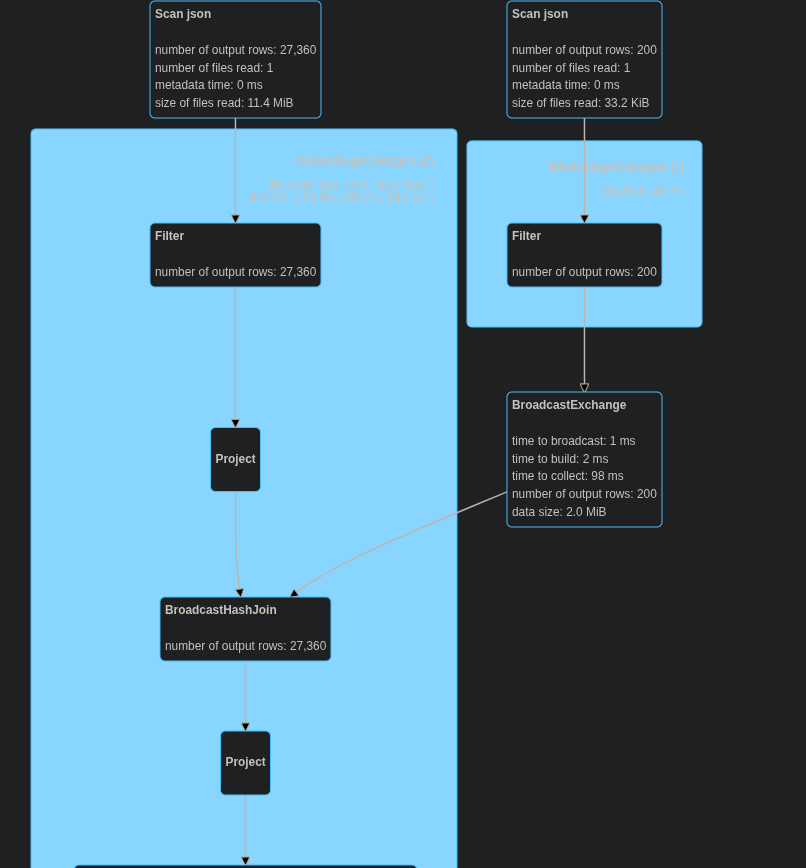

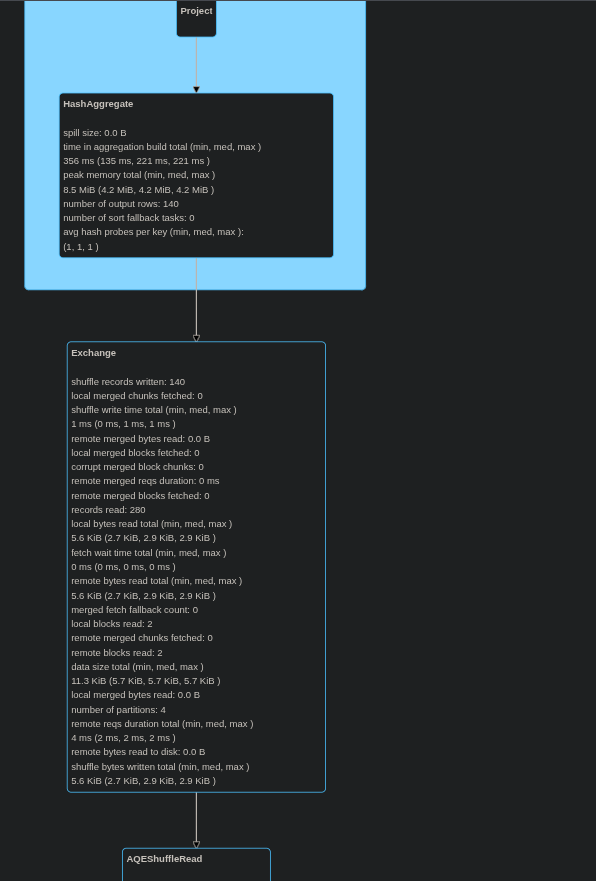

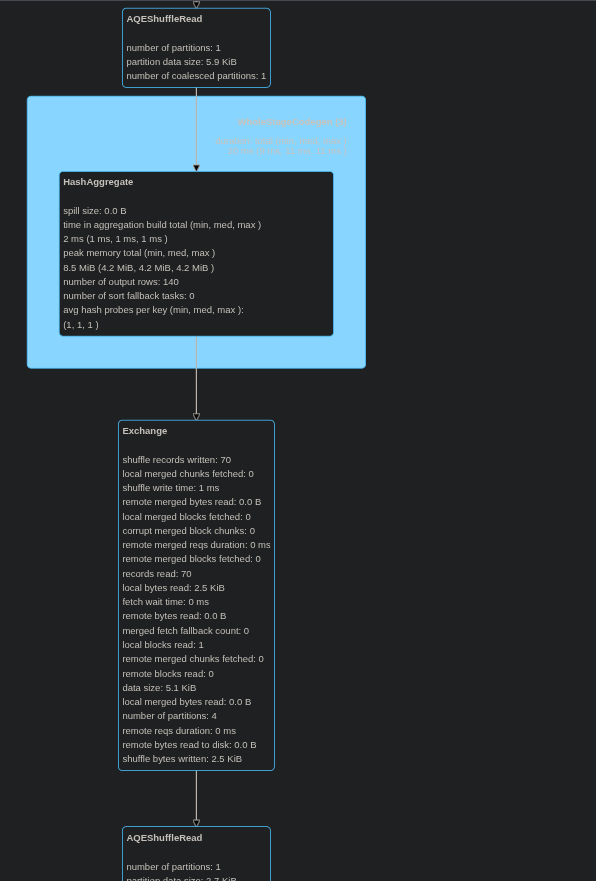

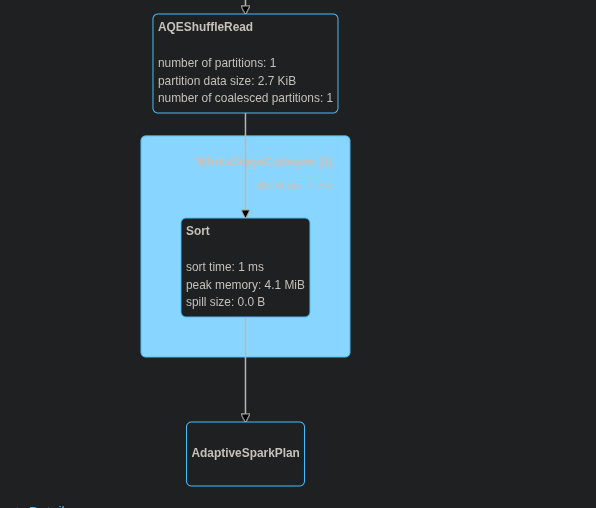

L’analyse produit 70 groupes ville/catégorie. Catalyst déplace le
filtre DELIVERED avant la jointure et conserve les colonnes utiles
au calcul.

Spark utilise une BroadcastHashJoin avec BuildRight. Le référentiel
de 200 restaurants est diffusé aux Executors, puis joint aux
27 360 événements livrés. Les doublons de Bronze contribuent aux
indicateurs.

L’agrégation calcule des sommes et des compteurs partiels avant un
shuffle par ville et catégorie. Un second échange prépare le tri
global. Le plan final présente des AQEShuffleRead coalesced, ce qui
montre le regroupement adaptatif des partitions. La capture avant
le tri final indique une partition de lecture et aucun débordement
sur disque pour le tri.